<a href="https://colab.research.google.com/github/andyotani/Machine-learning_26-27/blob/main/JS08/Tugas_Lab_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Tugas Lab 1


* Gunakan dataset CC_Customer_Dataset.csv dari Tugas Lab

* Buatlah model klasterisasi dengan menggunakan Agglomerative Clustering dengan seluruh variabel yang dapat digunakan.

* Buatlah scatterplot berdasarkan dataset menggunakan dua variabel, yaitu Avg_Credit_Limit dan Total_credit_card. Tunjukkan bentuk cluster-nya berdasarkan dua fitur tersebut.

* Tentukan nilai silhouette score dan DBI dari model.

### Langkah 1: Memuat dan Mempersiapkan Dataset

Di langkah ini, kita akan membaca file dataset, melakukan eksplorasi singkat, memilih variabel yang dapat digunakan untuk klasterisasi (variabel numerik), serta melakukan standarisasi data menggunakan `StandardScaler`.

In [4]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# Membaca dataset
df = pd.read_csv('/content/CC_Customer_Dataset.csv')

# Menampilkan 5 data pertama dan informasi dataset
display(df.head())
print(df.info())

# Memilih variabel numerik yang relevan untuk klasterisasi
# Mengabaikan kolom ID atau kolom non-numerik jika ada (misal Customer Key)
features = df.select_dtypes(include=[np.number])
if 'Customer Key' in features.columns:
    features = features.drop(columns=['Customer Key'])

# Mengisi nilai kosong (missing values) jika ada
features = features.fillna(features.median())

# Standarisasi data
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

print("Fitur yang digunakan untuk klasterisasi:", list(features.columns))

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB
None
Fitur yang digunakan untuk klasterisasi: ['Sl_No', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


### Langkah 2: Pembuatan Model Agglomerative Clustering

Kita akan melatih model `AgglomerativeClustering`. Sebagai contoh awal, kita akan menggunakan 3 klaster.

In [5]:
from sklearn.cluster import AgglomerativeClustering

# Membangun model Agglomerative Clustering
# Menentukan jumlah cluster (misal: n_clusters=3)
n_clusters = 3
model = AgglomerativeClustering(n_clusters=n_clusters, metric='euclidean', linkage='ward')
clusters = model.fit_predict(scaled_features)

# Menambahkan hasil klaster ke dataframe asli
df['Cluster'] = clusters
print(f"Model Agglomerative Clustering berhasil dibuat dengan {n_clusters} klaster.")

Model Agglomerative Clustering berhasil dibuat dengan 3 klaster.


### Langkah 3: Visualisasi Cluster dengan Scatterplot

Membuat scatterplot berdasarkan dataset menggunakan dua variabel: `Avg_Credit_Limit` dan `Total_credit_card` dengan warna titik sesuai dengan klasternya.

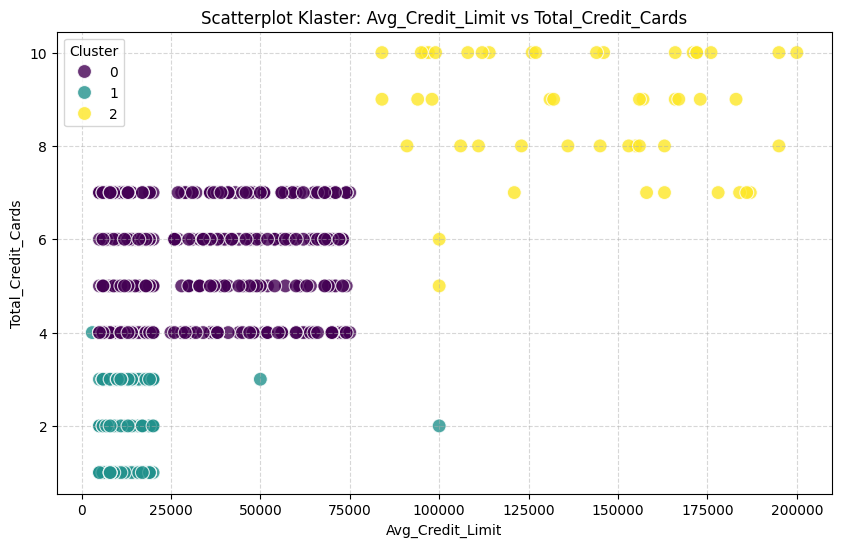

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Membuat scatterplot berdasarkan Avg_Credit_Limit dan Total_Credit_Cards
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='Avg_Credit_Limit',
    y='Total_Credit_Cards',
    hue='Cluster',
    palette='viridis',
    data=df,
    s=100,
    alpha=0.8
)

plt.title('Scatterplot Klaster: Avg_Credit_Limit vs Total_Credit_Cards')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.legend(title='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Langkah 4: Evaluasi Model (Silhouette Score & DBI)

Langkah terakhir adalah mengukur kualitas dari hasil klasterisasi menggunakan matrik **Silhouette Score** dan **Davies-Bouldin Index (DBI)**.

In [7]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Menghitung Silhouette Score
sil_score = silhouette_score(scaled_features, clusters)

# Menghitung Davies-Bouldin Index (DBI)
dbi_score = davies_bouldin_score(scaled_features, clusters)

print(f"Hasil Evaluasi Model:")
print(f"- Silhouette Score : {sil_score:.4f} (Semakin mendekati 1 semakin baik)")
print(f"- Davies-Bouldin Index (DBI): {dbi_score:.4f} (Semakin kecil nilainya semakin baik)")

Hasil Evaluasi Model:
- Silhouette Score : 0.5305 (Semakin mendekati 1 semakin baik)
- Davies-Bouldin Index (DBI): 0.6695 (Semakin kecil nilainya semakin baik)
